# AFRI Profile Visualization

This notebook provides comprehensive visualization tools for analyzing Automatic Frequency Range Identification (AFRI) profiles across different bird species classes.

## Overview

AFRI automatically identifies the most relevant frequency ranges for each species by analyzing positive training samples. This notebook visualizes:
- Raw AFRI profiles showing frequency importance
- Detected frequency ranges (minbin to maxbin)
- Profile overlays on actual spectrograms
- Grid views for comparing multiple classes

## 1. Setup

Import necessary libraries and configure paths for accessing the source code.

In [ ]:
import sys
import os
from pathlib import Path
import librosa

# Add src directory to path for imports
notebook_dir = Path.cwd()
project_root = notebook_dir.parent
src_path = project_root / 'src'
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from omegaconf import OmegaConf
import warnings
warnings.filterwarnings('ignore')

print(f"Project root: {project_root}")
print(f"Source path: {src_path}")
print("Setup complete!")

Project root: /media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5
Source path: /media/helios/Masters/Repository/dcase-few-shot-bioacoustic/baselines/dcase2024_task5/src
Setup complete!


## 2. Configuration

Load the training configuration and enable AFRI for frequency range detection.

In [2]:
# Load configuration
config_path = project_root / 'configs' / 'train.yaml'
cfg = OmegaConf.load(config_path)

# Enable AFRI in train_param
cfg.train_param.use_afri = True
cfg.train_param.afri_n_samples = 5  # Use first 5 samples
cfg.train_param.afri_value_threshold = 0.23
cfg.train_param.afri_search_threshold = 7
cfg.train_param.afri_debris_size = 10
cfg.train_param.afri_min_bin_expand = 2
cfg.train_param.afri_max_bin_expand = 6
cfg.train_param.afri_mask_mode = 'direct'

print("Configuration loaded successfully!")
print(f"AFRI enabled: {cfg.train_param.use_afri}")
print(f"AFRI n_samples: {cfg.train_param.afri_n_samples}")
print(f"AFRI threshold: {cfg.train_param.afri_value_threshold}")

Configuration loaded successfully!
AFRI enabled: True
AFRI n_samples: 5
AFRI threshold: 0.23


## 3. Dataset Loading

Initialize the dataset with AFRI enabled. This will compute frequency profiles for all classes during initialization.

In [3]:
from datamodules.components.dynamic_pcen_dataset import PrototypeDynamicArrayDataSet

# Initialize dataset with AFRI
print("Initializing dataset with AFRI...")
print(f"Using path: {cfg.path}")
print(f"Features: {cfg.features}")
print(f"Train params: {cfg.train_param}\n")

dataset = PrototypeDynamicArrayDataSet(
    path=cfg.path,
    features=cfg.features,
    train_param=cfg.train_param
)

Initializing dataset with AFRI...
Using path: {'root_dir': '/media/helios/Data/Uni/Masters/Dataset', 'train_dir': '${path.root_dir}/Development_Set/Training_Set', 'eval_dir': '${path.root_dir}/Development_Set/Validation_Set', 'test_dir': '${path.root_dir}/Test_Set', 'extra_train_dir': None, 'mask_dir': None}
Features: {'eps': 2e-16, 'fmax': 11025, 'fmin': 50, 'sr': 22050, 'n_fft': 1024, 'n_mels': 128, 'hop_mel': 256, 'feature_types': 'logmel', 'embedding_dim': 2048, 'drop_rate': 0.1, 'with_bias': False, 'non_linearity': 'leaky_relu', 'time_max_pool_dim': 4, 'layer_4': False, 'test_seglen_len_lim': 30, 'test_hoplen_fenmu': 3, 'use_cife': True, 'cife_channels': 128, 'cife_d_model': 128, 'cife_nhead': 4, 'cife_num_encoder_layers': 2, 'cife_num_decoder_layers': 2, 'cife_dim_feedforward': 256, 'cife_dropout': 0.1, 'cife_alpha': 0.3, 'cife_spatial_pool': True, 'cife_pool_size': [2, 16]}
Train params: {'exp_name': '${exp_name}', 'sr': 22050, 'seg_len': 0.2, 'n_shot': 5, 'k_way': 10, 'device':

100%|██████████| 174/174 [00:14<00:00, 11.88it/s]



✓ Loaded AFRI profiles from cache (key: 57d5812f...)
Loaded 46 class profiles from cache



In [66]:
from itertools import islice  
meta_dict = dict(islice(dataset.meta.items(),2))
meta_list = list(dict(islice(dataset.meta.items(),2)))
meta_dict.keys()
meta_dict["OVEN"]["file"]

['/media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set/BV/2015-09-04_08-04-59_unit03.wav',
 '/media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set/BV/2015-09-04_08-04-59_unit03.wav',
 '/media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set/BV/2015-09-04_08-04-59_unit03.wav',
 '/media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set/BV/2015-09-04_08-04-59_unit03.wav',
 '/media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set/BV/2015-09-04_08-04-59_unit03.wav',
 '/media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set/BV/2015-09-04_08-04-59_unit03.wav',
 '/media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set/BV/2015-09-04_08-04-59_unit03.wav',
 '/media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set/BV/2015-09-04_08-04-59_unit03.wav',
 '/media/helios/Data/Uni/Masters/Dataset/Development_Set/Training_Set/BV/2015-09-04_08-04-59_unit03.wav',
 '/media/helios/Data/Uni/Masters/Dataset/Devel

In [22]:
print(f"\nDataset initialized successfully!")
print(f"Number of classes: {len(dataset.classes)}")
print(f"Classes: {dataset.classes[:10]}...")  # Show first 10

# Check AFRI profiles
print(f"\nAFRI profiles computed for {len(dataset.classes)} classes")
print(f"Sample profile keys: {meta_list[:5]}")

# Show example profile structure
first_class = list(meta_dict.keys())[0]
first_profile = meta_dict[first_class]['afri_profile']
print(f"\nExample profile structure for '{first_class}':")
if first_profile:
    print(f"  Keys: {list(first_profile.keys())}")
    print(f"  Profile shape: {first_profile['raw_profile'].shape if 'raw_profile' in first_profile else 'N/A'}")
    print(f"  Detected range: [{first_profile.get('auto_minbin', 'N/A')}-{first_profile.get('auto_maxbin', 'N/A')}]")



Dataset initialized successfully!
Number of classes: 46
Classes: ['OVEN', 'SWTH', 'COYE', 'BBWA', 'BTBW', 'AMRE', 'RBGR', 'GCTH', 'WTSP', 'CHSP']...

AFRI profiles computed for 46 classes
Sample profile keys: ['OVEN', 'SWTH']

Example profile structure for 'OVEN':
  Keys: ['raw_profile', 'mask_weights', 'inverse_weights', 'auto_minbin', 'auto_maxbin', 'valid']
  Profile shape: (128,)
  Detected range: [124-125]


## 4. Visualization Functions

### Function 1: Simple Profile View

Visualizes the raw AFRI profile with detected frequency range overlay.

In [25]:
def visualize_afri_profile(class_name, profile, n_mels=128):
    """
    Visualize AFRI profile with detected frequency range.
    
    Args:
        class_name: Name of the species class
        profile: Dictionary containing AFRI profile data
        n_mels: Number of mel bins (default: 128)
    """
    # Validate profile
    if profile is None or 'raw_profile' not in profile:
        print(f"Invalid profile for {class_name}")
        return
    
    # Extract profile data
    freq_profile = profile['raw_profile']
    minbin = profile.get('minbin', 0)
    maxbin = profile.get('maxbin', n_mels - 1)
    auto_minbin = profile.get('auto_minbin', minbin)
    auto_maxbin = profile.get('auto_maxbin', maxbin)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, 4))
    
    # Plot profile as line with filled area
    freq_bins = np.arange(len(freq_profile))
    ax.plot(freq_bins, freq_profile, color='blue', linewidth=2, label='AFRI Profile')
    ax.fill_between(freq_bins, freq_profile, alpha=0.3, color='blue')
    
    # Draw detected frequency range rectangle
    rect_height = ax.get_ylim()[1] - ax.get_ylim()[0]
    rect = patches.Rectangle(
        (auto_minbin, ax.get_ylim()[0]),
        auto_maxbin - auto_minbin,
        rect_height,
        linewidth=2,
        edgecolor='red',
        facecolor='red',
        alpha=0.1,
        label='Detected Range'
    )
    ax.add_patch(rect)
    
    # Add vertical dashed lines at minbin and maxbin
    ax.axvline(minbin, color='green', linestyle='--', linewidth=1.5, label=f'Min Bin ({minbin})')
    ax.axvline(maxbin, color='orange', linestyle='--', linewidth=1.5, label=f'Max Bin ({maxbin})')
    
    # Annotate with bin values
    y_pos = ax.get_ylim()[1] * 0.9
    ax.text(auto_minbin, y_pos, f'{auto_minbin}', 
            ha='center', va='bottom', fontsize=10, color='red', fontweight='bold')
    ax.text(auto_maxbin, y_pos, f'{auto_maxbin}', 
            ha='center', va='bottom', fontsize=10, color='red', fontweight='bold')
    
    # Formatting
    ax.set_xlabel('Frequency Bin', fontsize=12)
    ax.set_ylabel('Importance Score', fontsize=12)
    ax.set_title(f'AFRI Profile: {class_name}\nDetected Range: [{auto_minbin}-{auto_maxbin}]', 
                 fontsize=14, fontweight='bold')
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, n_mels - 1)
    
    plt.tight_layout()
    plt.show()

print("Function 1 (visualize_afri_profile) defined successfully!")

Function 1 (visualize_afri_profile) defined successfully!


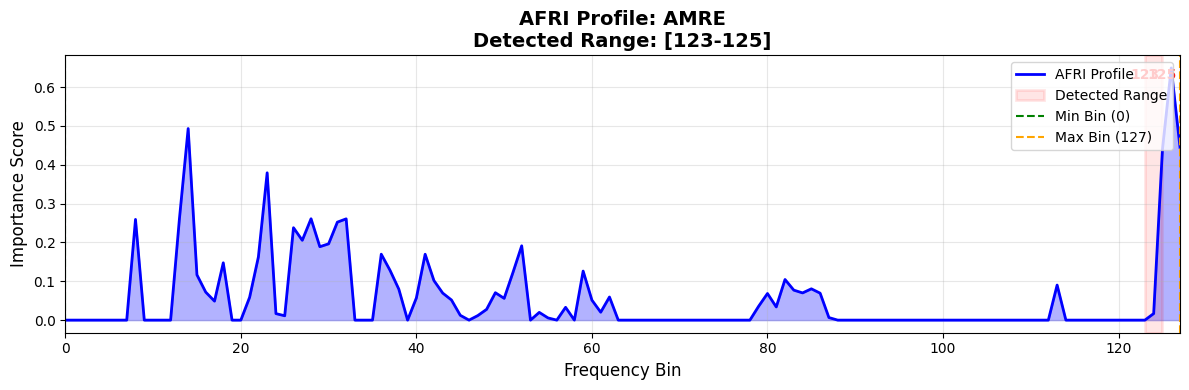

In [78]:
class_name = "AMRE"
visualize_afri_profile(class_name=class_name, profile=dataset.meta[class_name]["afri_profile"], n_mels=128)

### Function 2: Spectrogram Overlay

Shows AFRI profile alongside an example spectrogram with frequency range overlay.

In [79]:
def get_spectrogram(class_name, dataset, sample_idx = None):
    if sample_idx:
        segment_idx = sample_idx
    else:
        segment_idx = np.random.randint(len(dataset.meta[class_name]["info"]))
    
    filename = dataset.meta[class_name]["file"][segment_idx]
    start, end = dataset.meta[class_name]["info"][segment_idx]
    print(start,end)


In [80]:
def visualize_afri_with_spectrogram(class_name, dataset, n_mels=128):
    """
    Visualize AFRI profile with example spectrogram overlay.
    
    Args:
        class_name: Name of the species class
        profile: Dictionary containing AFRI profile data
        dataset: Dataset object for extracting spectrograms
        n_mels: Number of mel bins (default: 128)
    """
    # Validate profile
    profile = dataset.meta[class_name]["afri_profile"]

    if profile is None or 'raw_profile' not in profile:
        print(f"Invalid profile for {class_name}")
        return
    
    # Extract profile data
    freq_profile = profile['raw_profile']
    minbin = profile.get('minbin', 0)
    maxbin = profile.get('maxbin', n_mels - 1)
    auto_minbin = profile.get('auto_minbin', minbin)
    auto_maxbin = profile.get('auto_maxbin', maxbin)
    
    # Create figure with 2 subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4))
    
    # Left subplot: AFRI profile
    freq_bins = np.arange(len(freq_profile))
    ax1.plot(freq_bins, freq_profile, color='blue', linewidth=2, label='AFRI Profile')
    ax1.fill_between(freq_bins, freq_profile, alpha=0.3, color='blue')
    
    # Draw detected frequency range
    rect_height = ax1.get_ylim()[1] - ax1.get_ylim()[0]
    rect = patches.Rectangle(
        (auto_minbin, ax1.get_ylim()[0]),
        auto_maxbin - auto_minbin,
        rect_height,
        linewidth=2,
        edgecolor='red',
        facecolor='red',
        alpha=0.1,
        label='Detected Range'
    )
    ax1.add_patch(rect)
    
    ax1.axvline(minbin, color='green', linestyle='--', linewidth=1.5, label=f'Min Bin')
    ax1.axvline(maxbin, color='orange', linestyle='--', linewidth=1.5, label=f'Max Bin')
    
    ax1.set_xlabel('Frequency Bin', fontsize=12)
    ax1.set_ylabel('Importance Score', fontsize=12)
    ax1.set_title(f'AFRI Profile: {class_name}', fontsize=12, fontweight='bold')
    ax1.legend(loc='upper right', fontsize=9)
    ax1.grid(True, alpha=0.3)
    ax1.set_xlim(0, n_mels - 1)
    
    # Right subplot: Example spectrogram
    try:
        # Get first positive segment for this class
    
        # Get mel spectrogram from random positive sample
        spec = dataset.select_positive(class_name)
        p = get_spectrogram(class_name=class_name, dataset=dataset)
        # Plot spectrogram
        im = ax2.imshow(spec, aspect='auto', origin='lower', cmap='viridis', 
                        extent=[0, spec.shape[1], 0, n_mels])
        
        # Overlay horizontal lines at minbin/maxbin
        ax2.axhline(minbin, color='green', linestyle='--', linewidth=1.5, alpha=0.8)
        ax2.axhline(maxbin, color='orange', linestyle='--', linewidth=1.5, alpha=0.8)
        
        # Fill detected frequency range with transparency
        ax2.axhspan(auto_minbin, auto_maxbin, color='red', alpha=0.2)
        
        # Add colorbar
        cbar = plt.colorbar(im, ax=ax2)
        cbar.set_label('PCEN Magnitude', fontsize=10)
        
        ax2.set_xlabel('Time Frame', fontsize=12)
        ax2.set_ylabel('Frequency Bin', fontsize=12)
        ax2.set_title(f'Example Spectrogram\nRange: [{auto_minbin}-{auto_maxbin}]', 
                        fontsize=12, fontweight='bold')
        # else:
        #     ax2.text(0.5, 0.5, 'No positive samples available', 
        #             ha='center', va='center', transform=ax2.transAxes, fontsize=12)
        #     ax2.set_title('Example Spectrogram', fontsize=12, fontweight='bold')
    except Exception as e:
        ax2.text(0.5, 0.5, f'Error loading spectrogram:\n{str(e)}', 
                ha='center', va='center', transform=ax2.transAxes, fontsize=10)
        ax2.set_title('Example Spectrogram', fontsize=12, fontweight='bold')
    
    # plt.tight_layout()
    # plt.show()

print("Function 2 (visualize_afri_with_spectrogram) defined successfully!")

Function 2 (visualize_afri_with_spectrogram) defined successfully!


6935.393 6935.593


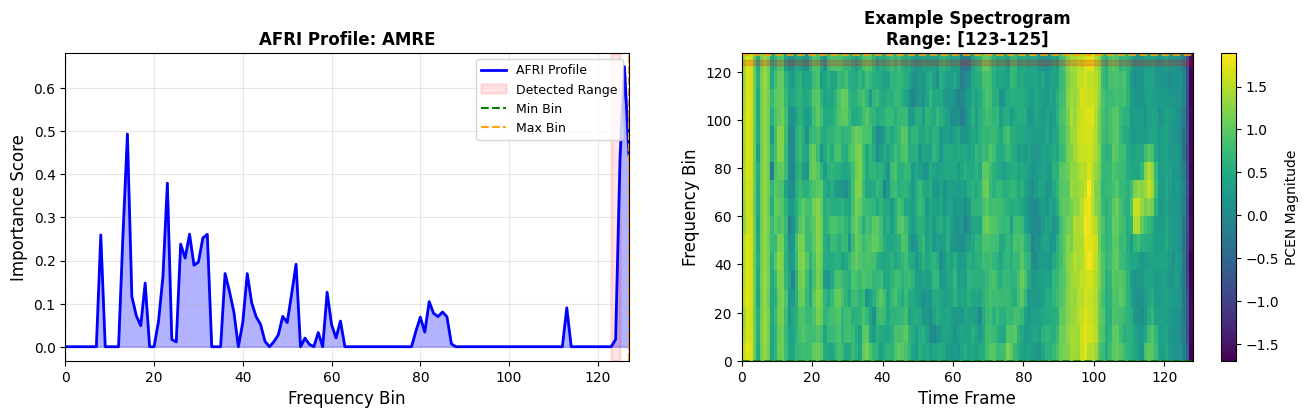

In [81]:
visualize_afri_with_spectrogram(class_name, dataset, n_mels=128)

### Function 3: Grid View

Displays AFRI profiles for all classes in a compact grid layout for easy comparison.

In [ ]:
def visualize_all_classes_grid(dataset, n_cols=3, n_mels=128):
    """
    Visualize AFRI profiles for all classes in a grid layout.
    
    Args:
        dataset: Dataset object containing AFRI profiles
        n_cols: Number of columns in the grid (default: 3)
        n_mels: Number of mel bins (default: 128)
    """
    # Get valid classes with profiles
    valid_classes = [(cls, prof) for cls, prof in dataset.afri_profiles.items() 
                     if prof is not None and 'profile' in prof]
    
    if len(valid_classes) == 0:
        print("No valid AFRI profiles found!")
        return
    
    # Calculate grid dimensions
    n_classes = len(valid_classes)
    n_rows = (n_classes + n_cols - 1) // n_cols
    
    # Create figure
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5*n_cols, 3*n_rows))
    if n_rows == 1 and n_cols == 1:
        axes = np.array([[axes]])
    elif n_rows == 1:
        axes = axes.reshape(1, -1)
    elif n_cols == 1:
        axes = axes.reshape(-1, 1)
    
    # Plot each class
    for idx, (class_name, profile) in enumerate(valid_classes):
        row = idx // n_cols
        col = idx % n_cols
        ax = axes[row, col]
        
        # Extract profile data
        freq_profile = profile['raw_profile']
        auto_minbin = profile.get('auto_minbin', 0)
        auto_maxbin = profile.get('auto_maxbin', n_mels - 1)
        
        # Plot profile
        freq_bins = np.arange(len(freq_profile))
        ax.plot(freq_bins, freq_profile, color='blue', linewidth=1.5)
        ax.fill_between(freq_bins, freq_profile, alpha=0.3, color='blue')
        
        # Draw detected range
        rect_height = ax.get_ylim()[1] - ax.get_ylim()[0]
        rect = patches.Rectangle(
            (auto_minbin, ax.get_ylim()[0]),
            auto_maxbin - auto_minbin,
            rect_height,
            linewidth=1.5,
            edgecolor='red',
            facecolor='red',
            alpha=0.1
        )
        ax.add_patch(rect)
        
        # Compact title with class name and range
        ax.set_title(f'{class_name}\n[{auto_minbin}-{auto_maxbin}]', 
                    fontsize=10, fontweight='bold')
        ax.set_xlabel('Freq Bin', fontsize=8)
        ax.set_ylabel('Score', fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.set_xlim(0, n_mels - 1)
        ax.tick_params(labelsize=8)
    
    # Hide unused subplots
    for idx in range(n_classes, n_rows * n_cols):
        row = idx // n_cols
        col = idx % n_cols
        axes[row, col].axis('off')
    
    plt.suptitle(f'AFRI Profiles - All Classes ({n_classes} total)', 
                 fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

print("Function 3 (visualize_all_classes_grid) defined successfully!")

## 5. Example Usage

### 5.1 Visualize Individual Classes (Simple Profile View)

Display AFRI profiles for the first 5 classes with detected frequency ranges.

In [ ]:
# Get first 5 classes with valid profiles
if hasattr(dataset, 'afri_profiles') and dataset.afri_profiles:
    valid_classes = [(cls, prof) for cls, prof in dataset.afri_profiles.items() 
                     if prof is not None and 'profile' in prof]
    
    print(f"Visualizing first 5 classes out of {len(valid_classes)} total\n")
    
    for class_name, profile in valid_classes[:5]:
        visualize_afri_profile(class_name, profile, n_mels=128)
else:
    print("No AFRI profiles available. Please ensure dataset was initialized with use_afri=True")

### 5.2 Visualize with Spectrogram Overlay

Show AFRI profile alongside an actual spectrogram to see how the detected range aligns with the audio content.

In [ ]:
# Visualize first 3 classes with spectrogram overlay
if hasattr(dataset, 'afri_profiles') and dataset.afri_profiles:
    valid_classes = [(cls, prof) for cls, prof in dataset.afri_profiles.items() 
                     if prof is not None and 'profile' in prof]
    
    print(f"Visualizing spectrograms for first 3 classes\n")
    
    for class_name, profile in valid_classes[:3]:
        visualize_afri_with_spectrogram(class_name, profile, dataset, n_mels=128)
else:
    print("No AFRI profiles available. Please ensure dataset was initialized with use_afri=True")

### 5.3 Grid View of All Classes

Display all AFRI profiles in a compact grid for quick comparison across species.

In [ ]:
# Visualize all classes in grid layout
visualize_all_classes_grid(dataset, n_cols=3, n_mels=128)

## 6. Analysis and Insights

### Key Observations

The visualizations above reveal several important patterns:

1. **Frequency Range Diversity**: Different species occupy distinct frequency ranges, which AFRI automatically identifies
2. **Profile Shapes**: The shape of the AFRI profile indicates how concentrated or dispersed the species' vocalizations are across frequencies
3. **Detection Accuracy**: The red overlay shows the automatically detected range, which should align with the peaks in the profile
4. **Spectrogram Validation**: The spectrogram overlay confirms that detected ranges correspond to actual audio energy

### Using These Insights

- **Frequency Masking**: AFRI profiles guide frequency masking during training to focus on relevant ranges
- **Data Augmentation**: Understanding frequency ranges helps design better augmentation strategies
- **Model Interpretation**: Profiles provide interpretable insights into what the model should focus on
- **Quality Control**: Unusual profiles may indicate data quality issues or mislabeled samples

## 7. Custom Analysis

Use the cells below for your own custom analysis and visualization experiments.

In [ ]:
# Custom analysis cell 1
# Example: Analyze specific class
# class_name = 'your_class_name'
# if class_name in dataset.afri_profiles:
#     profile = dataset.afri_profiles[class_name]
#     visualize_afri_profile(class_name, profile)


In [ ]:
# Custom analysis cell 2
# Example: Compare frequency ranges across classes
# ranges = {}
# for cls, prof in dataset.afri_profiles.items():
#     if prof and 'auto_minbin' in prof:
#         ranges[cls] = (prof['auto_minbin'], prof['auto_maxbin'])
# print(ranges)
